In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
# Load the dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Display the first 5 rows
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [4]:
df.shape

(2443651, 9)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


In [ ]:
# Missing values in each column
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

# Part 1: Understanding Product Categories
Business Question:
What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

### 1. Frequency Tables:

- Generate a frequency table for the product category.
- Which are the top 5 most listed product categories?

In [20]:
top_5_categories = df["category"].value_counts().head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

### 2. Visualizations:

- Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

Text(0, 0.5, 'Number of Listings')

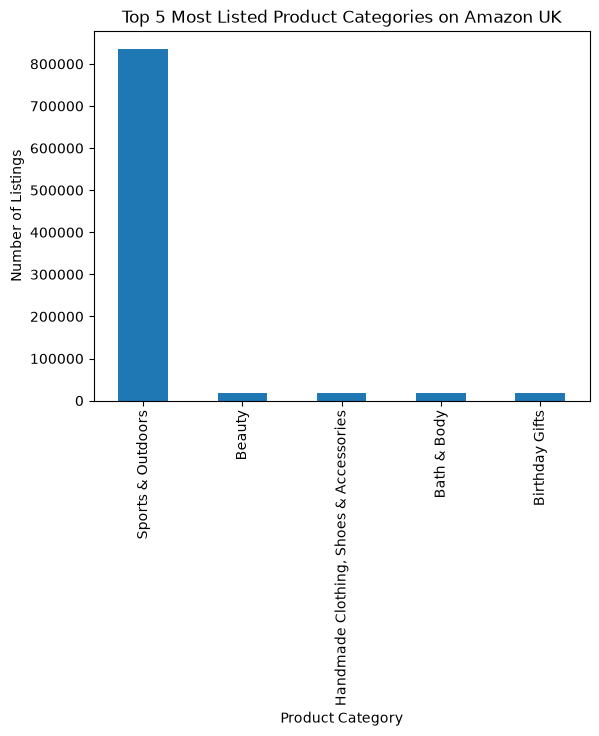

In [ ]:
# Bar chart
top_5_categories.plot(kind="bar")

# Titles and axis lables
plt.title("Top 5 Most Listed Product Categories on Amazon UK")
plt.xlabel("Product Category")
plt.ylabel("Number of Listings")
# plt.xticks(rotation=45, ha="right") # rotate category labels for readability

Text(0, 0.5, '')

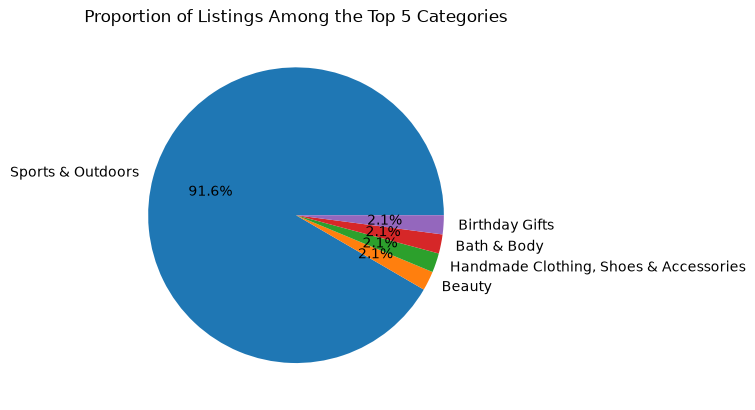

In [35]:
# Create a pie chart showing the proportions of the top 5 categories
top_5_categories.plot(kind="pie", autopct="%1.1f%%")

# Add a title
plt.title("Proportion of Listings Among the Top 5 Categories")

# Remove the default y-axis label
plt.ylabel("")

In [47]:
top_5_categories.value_counts

<bound method IndexOpsMixin.value_counts of category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64>

### Business interpretation
- Sports & Outdoors: 836'265 listings
- Beauty 19'312
- Handmade Clothing, Shoes & Accessories 19'229
- Bath & Body 19'092
- Birthday Gifts 18'978

Sports & Outdoors dominates the top 5 categories by listing count with approximately 91.6% of listings within this top-five subset.

# Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

### 1. Measures of Centrality:

- Calculate the mean, median, and mode for the price of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [ ]:
# Mean
df["price"].mean()

np.float64(89.24380943923661)

In [ ]:
# Median
df["price"].median()

np.float64(19.09)

In [ ]:
# Mode
df["price"].mode()

0    9.99
Name: price, dtype: float64

The average product price is £89.24, while the median price is £19.09 and the mode is £9.99.
The substantial difference between the mean and median suggests that the dataset may contain some high-priced products that increase the average.
The median may therefore provide a more representative measure of the typical product price. The most common price point is £9.99.

### 2. Measures of Dispersion:

- Determine the variance, standard deviation, range, and interquartile range for product price.
- How varied are the product prices? Are there any indicators of a significant spread in prices?

In [ ]:
# Variance
df["price"].var()

np.float64(119445.48532254901)

In [ ]:
# Standard deviation
df["price"].std()

np.float64(345.60886175349873)

In [ ]:
# Range
df_price_max = df["price"].max()
df_price_min = df["price"].min()

df_price_range = df_price_max - df_price_min
df_price_range

np.float64(100000.0)

In [ ]:
# Calculate first quartile (25%)
Q1 = df["price"].quantile(0.25)
print(f"First quartile: {Q1}")

# Calculate third quartile (75%)
Q3 = df["price"].quantile(0.75)
print(f"Third quartile: {Q3}")

# Calculate interquartile range
IQR = Q3 - Q1
print(f"Interquartile range: {IQR}")

First quartile: 9.99
Third quartile: 45.99
Interquartile range: 36.0


### Business interpretation
Product prices vary considerably. Most products are relatively affordable, with 50% of products priced between £9.99 and £45.99. However, some products are much more expensive, which increases the average price and the overall variation.

### 3. Visualizations:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices.
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

#### 1. Histogram — Product price distribution

Text(0, 0.5, 'Number of Products')

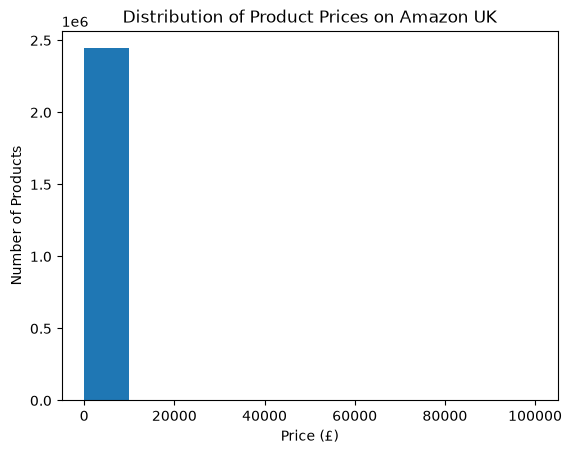

In [73]:
# Plot the distribution of product prices
df["price"].plot(kind="hist", bins=10)

# Add title and labels
plt.title("Distribution of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

#### Histogram focused on prices below £200

Text(0, 0.5, 'Number of Products')

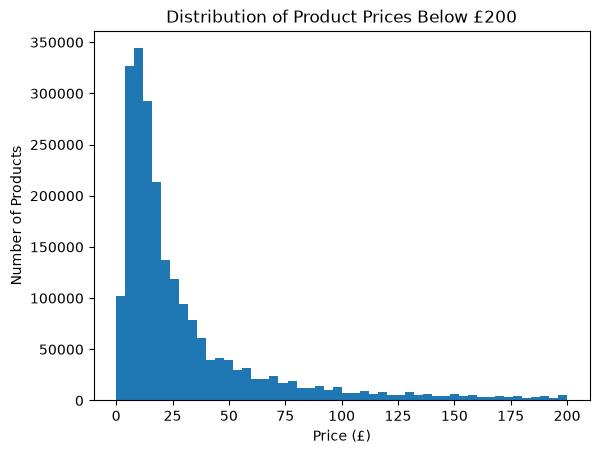

In [77]:
# Filter products priced below £200
df_price_under_200 = df[df["price"] < 200]

# Plot the distribution
df_price_under_200["price"].plot(kind="hist", bins=50)

plt.title("Distribution of Product Prices Below £200")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

Most products are concentrated in the lower price ranges, with the highest frequency around £15. The first histogram was difficult to interpret because a few extremely expensive products stretched the price scale. Filtering products priced below £200 made the distribution much clearer.

#### 2. Box plot — Identify potential outliers

Text(0.5, 0, 'Price (£)')

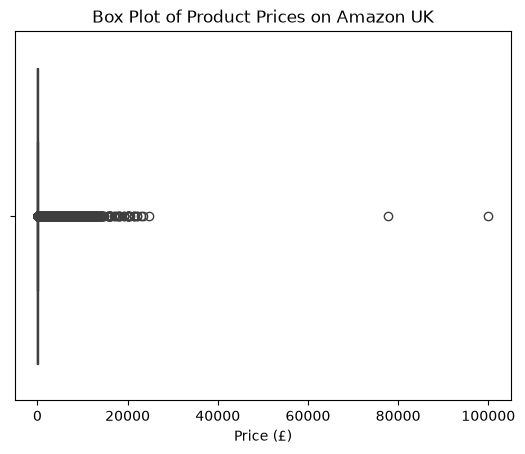

In [78]:
# Create a box plot of product prices
sns.boxplot(x=df["price"])

plt.title("Box Plot of Product Prices on Amazon UK")
plt.xlabel("Price (£)")

The box plot shows that some products are priced much higher than most others. These potential outliers contribute to the large difference between the mean and median prices. They should be investigated to determine whether they are genuine high-priced products or possible data errors.

# Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?


### 1. Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.
- How do customers generally rate products? Is there a common trend?

In [87]:
df["stars"].shape

(2443651,)

In [ ]:
df["stars"].mean()

np.float64(2.152836472966066)

In [84]:
df["stars"].median()

np.float64(0.0)

In [85]:
df["stars"].mode()

0    0.0
Name: stars, dtype: float64

In [86]:
# Count products with a rating of 0
(df["stars"] == 0).sum()

np.int64(1225641)

In [ ]:
# Count missing ratings
df["stars"].isna().sum()

np.int64(0)

In [89]:
# Count the frequency of each rating
df["stars"].value_counts().sort_index()

stars
0.0    1225641
1.0       8484
1.1          3
1.2         23
1.3         78
1.4        149
1.5        404
1.6        147
1.7        177
1.8        249
1.9        300
2.0       3901
2.1        540
2.2        602
2.3        734
2.4       1060
2.5       2103
2.6       1579
2.7       2104
2.8       2306
2.9       3341
3.0      12819
3.1       4679
3.2       5771
3.3       8269
3.4      10355
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.0      66089
4.1      65115
4.2      86871
4.3     112564
4.4     136165
4.5     151577
4.6     136995
4.7      94566
4.8      41858
4.9      11081
5.0     128492
Name: count, dtype: int64

In [95]:
df_ratings = df[df["stars"] > 0]

print(df_ratings["stars"].mean())
print(df_ratings["stars"].median())
print(df_ratings["stars"].mode())

4.319160762226911
4.4
0    4.5
Name: stars, dtype: float64


The average product rating is 4.32 stars, the median is 4.4 stars, and the most frequent rating is 4.5 stars. This suggests that customers generally rate products positively, with ratings tending to be high.

### 2. Measures of Dispersion:

- Determine the variance, standard deviation, and interquartile range for product rating.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [109]:
# Measures of dispersion
print("Variance:", df_ratings["stars"].var())
print("Standard deviation:", df_ratings["stars"].std())

Q1_ratings = df_ratings["stars"].quantile(0.25)
Q3_ratings = df_ratings["stars"].quantile(0.75)

print("Interquartile range:", Q3_ratings - Q1_ratings)

Variance: 0.3083433752387284
Standard deviation: 0.5552867504620729
Interquartile range: 0.5


The variance is 0.3083 and the standard deviation is approximately 0.56 stars, indicating relatively low variation in product ratings. The interquartile range is 0.5, meaning that the middle 50% of ratings are concentrated within a narrow range. Overall, ratings appear relatively consistent, although some variation in customer feedback remains.

### 3. Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [112]:
skewness_stars = df_ratings["stars"].skew()
kurtosis_stars = df_ratings["stars"].kurtosis()

skewness_stars, kurtosis_stars

(np.float64(-2.379568112212799), np.float64(9.78193769066435))

The skewness of −2.38 indicates a negatively skewed distribution, with most product ratings concentrated at the higher end and a tail extending toward lower ratings. The kurtosis of 9.78 indicates a more peaked distribution with heavier tails than a normal distribution. Overall, ratings tend to be high, although some products receive considerably lower ratings.

### 4. Visualizations:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

Text(0, 0.5, 'Number of Products')

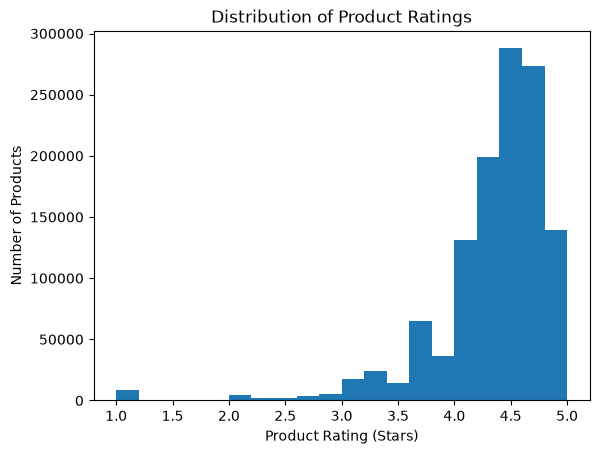

In [113]:
df_ratings["stars"].plot(kind="hist", bins=20)

plt.title("Distribution of Product Ratings")
plt.xlabel("Product Rating (Stars)")
plt.ylabel("Number of Products")

### Business interpretation

The histogram shows that product ratings are concentrated toward the higher end of the scale. This suggests that customers generally rate products positively. The most common individual rating is 4.5 stars.